# 05 – Abschluss und Rewards-Programm
## 1. Verbindliche Entscheidungen
**Datenstand:** 16.07.2023, Tagesende UTC. **Population:** ursprüngliche Kohorte mit
5.998 Nutzern und mehr als sieben Sessions ab 04.01.2023 im ursprünglichen Beobachtungsfenster.
486 Nutzer erfüllen diese Grenze am früheren Stichtag noch nicht. Sie bleiben bewusst
erhalten, um Population und Stichtagseffekt nicht gleichzeitig zu verändern. Das ist eine
begrenzte Kundenanalyse, keine repräsentative Stichprobe aller TravelTide-Nutzer und keine
vollständig historisch neu gebildete Kohorte.

**Methode:** k=3 als explorative Arbeitslösung, ergänzend transparente Regelgruppen.
k=2 trennt technisch stärker, fasst aber rund 94 % zusammen. Die feinere Dreierlösung
bleibt gegenüber dem früheren Stichtag weitgehend stabil. Cluster sind Verhaltensgruppen,
keine bewiesenen Präferenztypen. Demografie beschreibt die Gruppen und steuert keine Perks.

**Kommunikation:** Nur robuste Arbeitshypothesen erhalten einen hervorgehobenen Vorteil.
Alle anderen Nutzer erhalten eine allgemeine Einladung bzw. einen dokumentierten Test-/
Beobachtungsauftrag. Es wird keine Präferenz erfunden, um jede Zeile einem der fünf Vorteile zuzuweisen.

In [1]:
from pathlib import Path
import json
import hashlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML
import config
import eda_functions as eda

THEME=config.THEME
PERK_COLORS=config.PERK_COLORS
WIDTH=config.WIDTH
SOURCE=config.DATA_FEATURES_FOLDER/"cutoff_comparison_20230716"
FINAL=config.FINAL_DATA_FOLDER
meta=json.loads((SOURCE/"comparison_metadata.json").read_text(encoding="utf8"))
assert pd.Timestamp(meta["cutoff"])==pd.Timestamp(config.ANALYSIS_REFERENCE_DATE)
for filename,digest in meta["input_sha256"].items():
    assert hashlib.sha256((config.DATA_PREPROCESSING_FOLDER/filename).read_bytes()).hexdigest()==digest, f"Eingabedatei verändert: {filename}; Stichtagsvergleich erneut berechnen."
assert hashlib.sha256(config.BASELINE_FEATURE_NOTEBOOK.read_bytes()).hexdigest()==meta["source_sha256"]
features=pd.read_csv(SOURCE/"user_features_cutoff.csv").set_index("user_id")
decisions=pd.read_csv(SOURCE/"user_decisions_cutoff.csv").set_index("user_id")
labels=pd.read_csv(SOURCE/"user_cluster_changes.csv").set_index("user_id")["cluster_cutoff_refit_aligned"].astype(int)
assert features.index.is_unique and decisions.index.is_unique
assert set(features.index)==set(decisions.index)==set(labels.index)
decisions=decisions.reindex(features.index);labels=labels.reindex(features.index)
plt.rcParams.update({"figure.facecolor":THEME["background"],"axes.facecolor":THEME["surface"],"axes.titlecolor":THEME["primary"],"axes.titleweight":"bold","axes.labelcolor":THEME["text"],"text.color":THEME["text"],"xtick.color":THEME["text_muted"],"ytick.color":THEME["text_muted"],"axes.edgecolor":THEME["border"],"grid.color":THEME["border"],"axes.spines.top":False,"axes.spines.right":False,"axes.prop_cycle":plt.cycler(color=THEME["chart_colors"])})
def show_table(frame,title):
    eda.display_table(frame,title=title,card_width=WIDTH,max_height=450)
def note(text):display(HTML(f"<p>{text}</p>"))

## 2. Gruppenprofile und Interpretation
Namen beschreiben die beobachteten Mediane, keine Lebensstile oder sicheren Reiseabsichten.
Bei fehlenden Angaben beruhen verschiedene Kennzahlen auf unterschiedlichen Teilmengen.
Deshalb werden die gültigen Beobachtungszahlen zusätzlich ausgegeben.

,Segment,Nutzer,Anteil (%),booked_trip_count,booking_rate,both_booking_share,mean_hotel_nights,mean_flight_lead_days,observed_cancellation_rate,mean_bags_per_seat,long_haul_share
cluster,,,,,,,,,,,
0,Aktive Kombinationsbucher,4397,73.31,3.000000,0.375000,1.000000,2.714000,7.563000,0.000000,0.500000,0.000000
1,Seltenere Bucher mit längeren Hotelaufenthalten,1269,21.16,1.000000,0.125000,0.000000,7.000000,7.500000,0.000000,0.750000,0.000000
2,Früh planende Bucher mit mehr beobachteten Stornos,332,5.54,2.000000,0.300000,0.667000,6.000000,168.539000,0.500000,0.500000,0.500000


,booked_trip_count,booking_rate,both_booking_share,mean_hotel_nights,mean_flight_lead_days,observed_cancellation_rate,mean_bags_per_seat,long_haul_share
cluster,,,,,,,,
0,4397,4397,4397,4379,4395,4397,4395,4395
1,1269,1269,807,733,451,807,451,451
2,332,332,332,268,321,332,321,320


Aktive Kombinationsbucher : 4,397 Nutzer (73.3 %). Median: 3.0 gebuchte Reisen, 100% kombinierte Buchungssessions, 2.7 Hotelnächte und 7.6 Tage Flugvorlauf. Beobachtete Stornoquote im Median: 0%.

Seltenere Bucher mit längeren Hotelaufenthalten : 1,269 Nutzer (21.2 %). Median: 1.0 gebuchte Reisen, 0% kombinierte Buchungssessions, 7.0 Hotelnächte und 7.5 Tage Flugvorlauf. Beobachtete Stornoquote im Median: 0%.

Früh planende Bucher mit mehr beobachteten Stornos : 332 Nutzer (5.5 %). Median: 2.0 gebuchte Reisen, 67% kombinierte Buchungssessions, 6.0 Hotelnächte und 168.5 Tage Flugvorlauf. Beobachtete Stornoquote im Median: 50%.

Die Stornoquote bildet beobachtete Vorgänge ab. Lange Vorläufe, zukünftige Reisen und unterschiedliche Beobachtungszeiten schränken die Interpretation ein. Die Gruppenbezeichnung rechtfertigt allein keine kostenlose Stornierung.

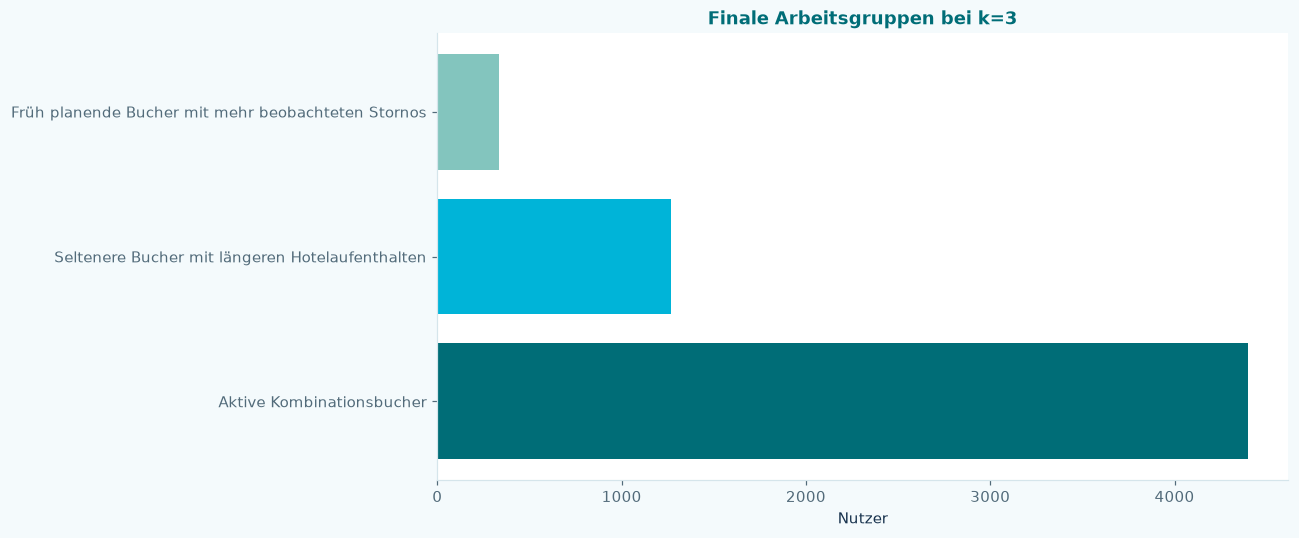

In [3]:
profile_columns=["booked_trip_count","booking_rate","both_booking_share","mean_hotel_nights","mean_flight_lead_days","observed_cancellation_rate","mean_bags_per_seat","long_haul_share"]
profiles=features[profile_columns].join(labels.rename("cluster")).groupby("cluster").median()
observations=features[profile_columns].join(labels.rename("cluster")).groupby("cluster").count()
sizes=labels.value_counts().sort_index()
early=int(profiles["mean_flight_lead_days"].idxmax())
remaining=profiles.drop(index=early)
active=int(remaining["booked_trip_count"].idxmax())
occasional=int(next(x for x in profiles.index if x not in [early,active]))
segment_names={active:"Aktive Kombinationsbucher",occasional:"Seltenere Bucher mit längeren Hotelaufenthalten",early:"Früh planende Bucher mit mehr beobachteten Stornos"}
profile_report=profiles.copy();profile_report.insert(0,"Segment",pd.Series(segment_names));profile_report.insert(1,"Nutzer",sizes);profile_report.insert(2,"Anteil (%)",sizes/len(features)*100)
show_table(profile_report.round(3),"Finale k=3-Gruppen: Medianprofile")
show_table(observations,"Gültige Beobachtungen für die Gruppenbeschreibung")
for label,row in profile_report.iterrows():
    note(f"<b>{row['Segment']}</b>: {int(row['Nutzer']):,} Nutzer ({row['Anteil (%)']:.1f} %). Median: {row['booked_trip_count']:.1f} gebuchte Reisen, {row['both_booking_share']:.0%} kombinierte Buchungssessions, {row['mean_hotel_nights']:.1f} Hotelnächte und {row['mean_flight_lead_days']:.1f} Tage Flugvorlauf. Beobachtete Stornoquote im Median: {row['observed_cancellation_rate']:.0%}.")
note("Die Stornoquote bildet beobachtete Vorgänge ab. Lange Vorläufe, zukünftige Reisen und unterschiedliche Beobachtungszeiten schränken die Interpretation ein. Die Gruppenbezeichnung rechtfertigt allein keine kostenlose Stornierung.")
fig,ax=plt.subplots(figsize=(12,5))
ax.barh([segment_names[x] for x in sizes.index],sizes.values,color=THEME["chart_colors"][:3])
ax.set(title="Finale Arbeitsgruppen bei k=3",xlabel="Nutzer");fig.tight_layout();plt.show()

## 3. Finale Nutzerdatei: Vorteil oder nächste Aktion
Die fünf Hypothesen wurden geprüft. Mahlzeiten haben lediglich einen indirekten
Langstrecken-Proxy und erhalten deshalb keinen automatischen Vorschlag. Auch für
Stornierung entsteht unter den strengen Varianten nicht zwingend eine robuste Zuordnung.
„Keine robuste Empfehlung“ ist ein zulässiges Analyseergebnis und kein zusätzliches Perk.
Die Datei trennt Vorschlag, tatsächliche Kommunikationsvariante und nächsten Prüfschritt.
Ein kontrollierter Test muss den Nutzen der Regel noch bestätigen.

,Nutzer
recommended_perk,
Keine robuste Empfehlung,5827
Erste Hotelnacht kostenlos,128
Kostenloses Gepäck,38
Exklusive Rabatte,5


,Nutzer
status,
Wenig Buchungsbeobachtungen,2361
Empfindlich gegenüber Annahmen,1646
Ähnliche Kandidaten / Gleichstand,1239
Keine beobachtete Buchung,462
Robuste Arbeitshypothese,171
Keine ausreichende direkte Evidenz,119


,cluster,segment,rule_segment,reference_date,recommended_perk,communication_variant,status,reason,baseline_recommendation,candidate_1,candidate_2,score_gap,sensitivity_agreement,next_action,meal_test_proxy,cancel_n,cancel_x,bag_n,bag_x,discount_n,discount_x,hotel_n
user_id,,,,,,,,,,,,,,,,,,,,,,
23557,1,Seltenere Bucher mit längeren Hotelaufenthalten,Wenig Beobachtungen,2023-07-16T23:59:59.999999Z,-,Allgemeine Einladung ohne hervorgehobenen Vorteil,Wenig Buchungsbeobachtungen,Keine eindeutige und über alle geprüften Varianten stabile Perk-Hypothese. Kandidaten und nächste Aktion beachten.,-,-,-,0.000000,1.000000,Weiter beobachten; allgemeine Einladung,False,2,0,0,0,2,1,2
94883,0,Aktive Kombinationsbucher,Wenig Beobachtungen,2023-07-16T23:59:59.999999Z,-,Allgemeine Einladung ohne hervorgehobenen Vorteil,Wenig Buchungsbeobachtungen,Keine eindeutige und über alle geprüften Varianten stabile Perk-Hypothese. Kandidaten und nächste Aktion beachten.,-,-,-,0.000000,1.000000,Weiter beobachten; allgemeine Einladung,False,2,0,2,1,4,0,1
101486,1,Seltenere Bucher mit längeren Hotelaufenthalten,Wenig Beobachtungen,2023-07-16T23:59:59.999999Z,-,Allgemeine Einladung ohne hervorgehobenen Vorteil,Wenig Buchungsbeobachtungen,Keine eindeutige und über alle geprüften Varianten stabile Perk-Hypothese. Kandidaten und nächste Aktion beachten.,-,-,-,0.000000,0.916667,Weiter beobachten; allgemeine Einladung,False,2,0,1,0,3,0,2
101961,0,Aktive Kombinationsbucher,Gemischtes Reiseverhalten,2023-07-16T23:59:59.999999Z,-,Allgemeine Einladung ohne hervorgehobenen Vorteil,Empfindlich gegenüber Annahmen,Keine eindeutige und über alle geprüften Varianten stabile Perk-Hypothese. Kandidaten und nächste Aktion beachten.,Erste Hotelnacht kostenlos,Erste Hotelnacht kostenlos,Kostenloses Gepäck,0.129406,0.833333,Regeln prüfen; vorläufig allgemeine Einladung,False,5,0,5,2,10,1,5
106907,2,Früh planende Bucher mit mehr beobachteten Stornos,Wenig Beobachtungen,2023-07-16T23:59:59.999999Z,-,Allgemeine Einladung ohne hervorgehobenen Vorteil,Wenig Buchungsbeobachtungen,Keine eindeutige und über alle geprüften Varianten stabile Perk-Hypothese. Kandidaten und nächste Aktion beachten.,-,-,-,0.000000,1.000000,Weiter beobachten; allgemeine Einladung,False,1,0,1,1,2,0,1
118043,0,Aktive Kombinationsbucher,Gepäck,2023-07-16T23:59:59.999999Z,-,Allgemeine Einladung ohne hervorgehobenen Vorteil,Empfindlich gegenüber Annahmen,Keine eindeutige und über alle geprüften Varianten stabile Perk-Hypothese. Kandidaten und nächste Aktion beachten.,Kostenloses Gepäck,Kostenloses Gepäck,Erste Hotelnacht kostenlos,0.272780,0.916667,Regeln prüfen; vorläufig allgemeine Einladung,False,5,0,3,3,7,2,4
120851,1,Seltenere Bucher mit längeren Hotelaufenthalten,Wenig Beobachtungen,2023-07-16T23:59:59.999999Z,-,Allgemeine Einladung ohne hervorgehobenen Vorteil,Wenig Buchungsbeobachtungen,Keine eindeutige und über alle geprüften Varianten stabile Perk-Hypothese. Kandidaten und nächste Aktion beachten.,-,-,-,0.000000,1.000000,Weiter beobachten; allgemeine Einladung,False,1,0,1,0,2,0,1
125845,0,Aktive Kombinationsbucher,Gepäck,2023-07-16T23:59:59.999999Z,-,Allgemeine Einladung ohne hervorgehobenen Vorteil,Empfindlich gegenüber Annahmen,Keine eindeutige und über alle geprüften Varianten stabile Perk-Hypothese. Kandidaten und nächste Aktion beachten.,Erste Hotelnacht kostenlos,Erste Hotelnacht kostenlos,Kostenloses Gepäck,0.181234,0.916667,Regeln prüfen; vorläufig allgemeine Einladung,False,3,0,3,2,6,1,3
133058,1,Seltenere Bucher mit längeren Hotelaufenthalten,Wenig Beobachtungen,2023-07-16T23:59:59.999999Z,-,Allgemeine Einladung ohne hervorgehobenen Vorteil,Wenig Buchungsbeobachtungen,Keine eindeutige und über alle geprüften Varianten stabile Perk-Hypothese. Kandidaten und nächste Aktion beachten.,-,-,-,0.000000,1.000000,Weiter beobachten; allgemeine Einladung,False,1,0,1,0,1,0,0


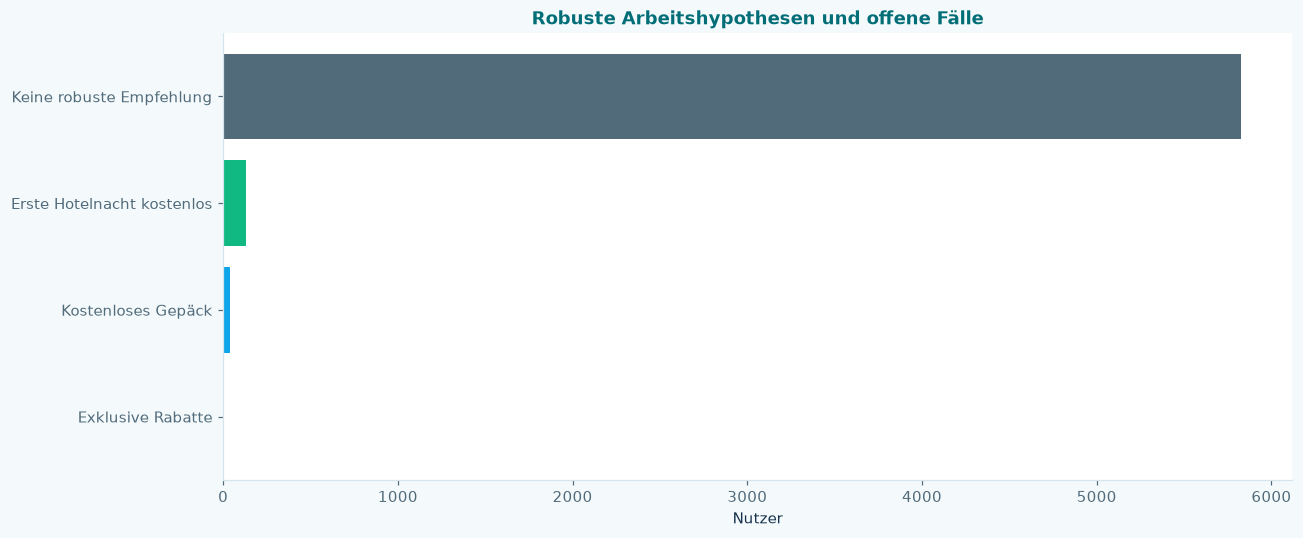

171 Nutzer erhalten einen hervorgehobenen Perk-Vorschlag. Für 5,827 Nutzer bleibt die Kommunikation allgemein bzw. wird als Test-/Beobachtungsauftrag behandelt. Dies beschreibt die konservative Regel, nicht die tatsächliche Verteilung von Präferenzen.

In [5]:
final_users=features.copy()
final_users["cluster"]=labels
final_users["segment"]=labels.map(segment_names)
final_users["rule_segment"]=decisions["rule_segment"]
final_users["reference_date"]=config.ANALYSIS_REFERENCE_DATE
for column in ["recommended_perk","baseline_recommendation","candidate_1","candidate_2","score_gap","sensitivity_agreement","status","next_action","meal_test_proxy"]:
    final_users[column]=decisions[column]
final_users["communication_variant"]=final_users["recommended_perk"].fillna("Allgemeine Einladung ohne hervorgehobenen Vorteil")
reasons={"Erste Hotelnacht kostenlos":"Hotelbuchungsanteil und relativer Nutzen einer Nacht, über alle geprüften Varianten stabil.","Kostenloses Gepäck":"Wiederholter beobachteter Gepäckbedarf, über alle geprüften Varianten stabil.","Exklusive Rabatte":"Wiederholte rabattierte Buchungskomponenten, über alle geprüften Varianten stabil.","Kostenlose Stornierung":"Beobachtete Stornos bei gebuchten Reisen, über alle geprüften Varianten stabil."}
final_users["reason"]=final_users["recommended_perk"].map(reasons).fillna("Keine eindeutige und über alle geprüften Varianten stabile Perk-Hypothese. Kandidaten und nächste Aktion beachten.")
action_columns=["cluster","segment","rule_segment","reference_date","recommended_perk","communication_variant","status","reason","baseline_recommendation","candidate_1","candidate_2","score_gap","sensitivity_agreement","next_action","meal_test_proxy"]
actions=final_users[action_columns].join(decisions[["cancel_n","cancel_x","bag_n","bag_x","discount_n","discount_x","hotel_n"]])
assert len(actions)==5998 and actions.index.is_unique
assert actions["communication_variant"].notna().all() and actions["next_action"].notna().all()
assert actions.loc[actions.recommended_perk.notna(),"sensitivity_agreement"].eq(1).all()
counts=actions.recommended_perk.fillna("Keine robuste Empfehlung").value_counts()
status_counts=actions.status.value_counts()
show_table(counts.rename("Nutzer").to_frame(),"Finale robuste Vorschläge")
show_table(status_counts.rename("Nutzer").to_frame(),"Unsicherheit und nächste Schritte")
show_table(actions.head(20),"Beispielzeilen der finalen Nutzerdatei")
perk_labels={"Kostenlose Stornierung":"Free Cancellation","Kostenloses Gepäck":"Free Baggage","Kostenlose Mahlzeiten":"Complimentary Meals","Erste Hotelnacht kostenlos":"First Night Free","Exklusive Rabatte":"Member Discounts"}
fig,ax=plt.subplots(figsize=(12,5));ordered=counts.sort_values()
ax.barh(ordered.index,ordered.values,color=[PERK_COLORS.get(perk_labels.get(x,x),THEME["text_muted"]) for x in ordered.index])
ax.set(title="Robuste Arbeitshypothesen und offene Fälle",xlabel="Nutzer");fig.tight_layout();plt.show()
note(f"{int(actions.recommended_perk.notna().sum()):,} Nutzer erhalten einen hervorgehobenen Perk-Vorschlag. Für {int(actions.recommended_perk.isna().sum()):,} Nutzer bleibt die Kommunikation allgemein bzw. wird als Test-/Beobachtungsauftrag behandelt. Dies beschreibt die konservative Regel, nicht die tatsächliche Verteilung von Präferenzen.")

## 4. Erfolgsmessung und kontrollierter Test
**Primäre Frage:** Erhöht eine personalisierte Hervorhebung die Anmeldung zum Rewards-Programm?

| Bestandteil | Vorab festgelegter Plan |
|---|---|
| Randomisierung | pro Nutzer, innerhalb der vorgeschlagenen Perk-/Evidenzgruppen |
| Kontrolle | allgemeine Einladung mit demselben vollständigen Leistungsangebot |
| Behandlung | gleicher Inhalt, aber der vorgeschlagene Vorteil wird hervorgehoben |
| Primäre Kennzahl | Anmeldung innerhalb von 14 Tagen je randomisiertem Nutzer (Intention-to-treat) |
| Sekundäre Kennzahlen | Buchung binnen 30 Tagen, erneute Aktivität/Buchung binnen 60 Tagen |
| Wirtschaftlichkeit | tatsächlich eingelöste Vorteils-Kosten und Deckungsbeitrag pro randomisiertem Nutzer, soweit verfügbar |
| Schutzkennzahlen | Abmeldungen, Beschwerden, Stornos; keine zusätzlichen Vorteile ohne Freigabe |
| Unsichere Fälle | allgemeine Einladung; getrennte Kandidatentests nur bei ausreichender Stichprobe |
| Mahlzeiten | separate Hypothese, derzeit kein automatisch zugewiesener Favorit |
| Auswertung | vorab definierter Zeitraum, absolute Prozentpunktdifferenz mit Unsicherheit; keine tägliche Erfolgsentscheidung |

Die vorhandenen 171 robusten Vorschläge sind kein ausreichender Beleg für die nötige
Teststärke. Vor dem Test müssen aktuelle Bestandsgrößen, Basis-Anmelderate, wirtschaftlich
relevanter Mindesteffekt und erforderliche Stichprobe erhoben werden. Keine erfundene
Conversion-Basis, kein unbegründeter Stichprobenumfang. Mehrere Perk-Tests erfordern eine
vorab festgelegte Korrektur bzw. eine begrenzte Zahl primärer Vergleiche.

Die Analyse simuliert und plant den Test; sie versendet keine Einladungen und behauptet
keinen bereits realisierten Effekt. Vor Live-Nutzung sind Kundenbestand und Daten zu aktualisieren.

## 5. Grenzen und verbindliche Übergabe
- Der Datenbruch ab 21.07.2023 begründet den früheren Stichtag. Seine technische Ursache ist nicht bewiesen.
- Der April-Dip betrifft primär die Wiederkehr bekannter Nutzer; Kampagnen und Saisonalität bleiben Hypothesen.
- Die ursprüngliche Population bleibt selektiert. 486 Nutzer erfüllen am früheren Stichtag die Mindestaktivität noch nicht.
- Aktuelle Preis-/Stammdaten sind keine historisch versionierten Daten. Flug-Gesamtpreisinterpretation bleibt vorläufig.
- Stornos sind beobachtete Ereignisse, keine sichere finale Teilbuchungsbilanz.
- Die breite Unsicherheit der Perk-Zuordnung bleibt sichtbar. Ein erzwungener Favorit würde mehr Sicherheit vortäuschen als die Daten tragen.

Der Export enthält alle Nutzer, Gruppenprofile, Beobachtungszahlen, Entscheidungen und ein
Manifest mit Stichtag, Quellprüfsummen und Methodik. Die bestehenden Eingabedateien bleiben unverändert.

In [8]:
FINAL.mkdir(parents=True,exist_ok=True)
final_users.reset_index().to_csv(FINAL/"users_final.csv",index=False)
actions.reset_index().to_csv(FINAL/"user_perk_actions.csv",index=False)
profile_report.to_csv(FINAL/"segment_profiles.csv")
observations.to_csv(FINAL/"segment_profile_observations.csv")
counts.rename("users").to_csv(FINAL/"perk_summary.csv")
status_counts.rename("users").to_csv(FINAL/"evidence_summary.csv")
manifest={"reference_date":config.ANALYSIS_REFERENCE_DATE,"population":"Originalkohorte unverändert","users":len(actions),"users_below_eight_sessions_at_cutoff":int(features.session_count.lt(8).sum()),"sessions":int(features.session_count.sum()),"cluster_method":"K-Means k=3, Neufit am Stichtag; Nummern zur Baseline angeglichen","robust_perk_recommendations":int(actions.recommended_perk.notna().sum()),"general_or_test_actions":int(actions.recommended_perk.isna().sum()),"source_metadata":meta,"not_a_measured_preference":True}
(FINAL/"release_manifest.json").write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding="utf8")
print(f"Abschlussstand: {len(actions):,} Nutzer; {int(features.session_count.sum()):,} Sessions; {int(actions.recommended_perk.notna().sum()):,} robuste Perk-Arbeitshypothesen.")
print(f"Finale Nutzerdatei: {FINAL/'user_perk_actions.csv'}")